# Comparison of scenarios

In [1]:
mt_rate = 0.1

output_name = 'taunton_worcester'

In [2]:
import contextily as ctx
import geopandas
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [3]:
base_path = "./output/results_full_current_hospitals.csv"
comparitor_path = "./output/results_full_taunton_and_worcester.csv"

base_data = pd.read_csv(base_path)
comparitor_data = pd.read_csv(comparitor_path)

hospitals = pd.read_csv("./data/stroke_hospitals_2025.csv", index_col='Postcode')

In [4]:
base_data.head()

,LSOA,nearest_ivt_unit,nearest_ivt_time,nearest_ivt_unit_no_bias,nearest_ivt_time_no_bias,nearest_mt_unit,nearest_mt_time,transfer_unit,transfer_required,transfer_time,...,lvo_mothership_ivt_mt_utility_shift,drip_ship_utility_shift,mothership_utility_shift,nlvo_drip_ship_ivt_improvement_over_no_treatment,lvo_drip_ship_ivt_improvement_over_no_treatment,no_treatment_mrs_0-2,drip_ship_mrs_0-2,drip_ship_mrs_0-2_improvement_over_no_treatment,mothership_mrs_0-2,mothership_mrs_0-2_improvement_over_no_treatment
0,ADUR001A,BN25BE,10,BN25BE,11,BN25BE,11,BN25BE,False,0,...,0.155584,0.114428,0.124652,0.120947,0.060172,0.4855,0.608202,0.122702,0.619167,0.133667
1,ADUR001B,BN25BE,11,BN25BE,12,BN25BE,12,BN25BE,False,0,...,0.154986,0.113964,0.124185,0.120497,0.059881,0.4855,0.607699,0.122199,0.618658,0.133158
2,ADUR001C,BN112DH,11,BN112DH,11,BN25BE,13,BN25BE,True,24,...,0.154388,0.109743,0.123719,0.120497,0.059881,0.4855,0.603213,0.117713,0.618149,0.132649
3,ADUR001D,BN25BE,11,BN25BE,12,BN25BE,12,BN25BE,False,0,...,0.154986,0.113964,0.124185,0.120497,0.059881,0.4855,0.607699,0.122199,0.618658,0.133158
4,ADUR001E,BN112DH,10,BN112DH,10,BN25BE,13,BN25BE,True,24,...,0.154388,0.110205,0.123719,0.120947,0.060172,0.4855,0.603713,0.118213,0.618149,0.132649


In [5]:
comparison = pd.DataFrame()
comparison['lsoa'] = base_data['area_lower']
comparison['admissions'] = base_data['Admissions_2025_Est']
comparison['base_ivt_unit'] = base_data['nearest_ivt_unit']
comparison['comparitor_ivt_unit'] = comparitor_data['nearest_ivt_unit']
comparison['base_mt_unit'] = base_data['nearest_mt_unit']
comparison['comparitor_mt_unit'] = comparitor_data['nearest_mt_unit']
comparison['base_transfer_in_MT'] = base_data['transfer_required']
comparison['comparitor_transfer_in_MT'] = comparitor_data['transfer_required']
comparison['base_ivt_time'] = base_data['nearest_ivt_unit_no_bias']
comparison['comparitor_ivt_time'] = comparitor_data['nearest_ivt_unit_no_bias']
comparison['base_mt_time'] = base_data['nearest_mt_time']
comparison['comparitor_mt_time'] = comparitor_data['nearest_mt_time']
comparison['base_mrs_0-2_per_1000'] = base_data['drip_ship_mrs_0-2'] * 1000
comparison['comparitor_mrs_0-2_per_1000'] = comparitor_data['drip_ship_mrs_0-2'] * 1000
comparison['change_in_mrs_0-2_per_1000'] = comparison['comparitor_mrs_0-2_per_1000'] - comparison['base_mrs_0-2_per_1000']
comparison['changed'] = 1.0 * (comparison['comparitor_mrs_0-2_per_1000'] > comparison['base_mrs_0-2_per_1000'])

In [6]:
comparison.head()

,lsoa,admissions,base_ivt_unit,comparitor_ivt_unit,base_mt_unit,comparitor_mt_unit,base_transfer_in_MT,comparitor_transfer_in_MT,base_ivt_time,comparitor_ivt_time,base_mt_time,comparitor_mt_time,base_mrs_0-2_per_1000,comparitor_mrs_0-2_per_1000,change_in_mrs_0-2_per_1000,changed
0,Adur 001A,1.49403,BN25BE,BN25BE,BN25BE,BN25BE,False,False,BN25BE,BN25BE,11,11,608.201855,608.201855,0.0,0.0
1,Adur 001B,1.86762,BN25BE,BN25BE,BN25BE,BN25BE,False,False,BN25BE,BN25BE,12,12,607.698551,607.698551,0.0,0.0
2,Adur 001C,2.24110,BN112DH,BN112DH,BN25BE,BN25BE,True,True,BN112DH,BN112DH,13,13,603.212930,603.212930,0.0,0.0
3,Adur 001D,2.24110,BN25BE,BN25BE,BN25BE,BN25BE,False,False,BN25BE,BN25BE,12,12,607.698551,607.698551,0.0,0.0
4,Adur 001E,4.10862,BN112DH,BN112DH,BN25BE,BN25BE,True,True,BN112DH,BN112DH,13,13,603.713490,603.713490,0.0,0.0


In [7]:
# Get unique base IVT units
base_ivt_units = comparison['base_ivt_unit'].unique().tolist()

# Set up the dataframe with base IVT units as the index
comparison_by_ivt_unit = pd.DataFrame(index=base_ivt_units)

# Add hospital details
comparison_by_ivt_unit['SSNAP_name'] = hospitals.loc[
    base_ivt_units, 'SSNAP name'
]
comparison_by_ivt_unit['Hospital_City'] = hospitals.loc[
    base_ivt_units, 'Hospital_City'
]

for unit in base_ivt_units:
    base_ivt = comparison['base_ivt_unit'] == unit
    comparator_ivt = comparison['comparitor_ivt_unit'] == unit
    base_mt = comparison['base_mt_unit'] == unit
    comparator_mt = comparison['comparitor_mt_unit'] == unit

    # First admissions
    base_admissions = comparison.loc[base_ivt, 'admissions'].sum()
    comparator_admissions = comparison.loc[
        comparator_ivt, 'admissions'
    ].sum()
    comparison_by_ivt_unit.loc[unit, 'base_first_admissions'] = int(
        base_admissions
    )
    comparison_by_ivt_unit.loc[
        unit, 'comparator_first_admissions'
    ] = int(comparator_admissions)

    # MT admissions
    base_mt_admissions = comparison.loc[base_mt, 'admissions'].sum()
    comparator_mt_admissions = comparison.loc[
        comparator_mt, 'admissions'
    ].sum()
    comparison_by_ivt_unit.loc[unit, 'base_all_MT_admissions'] = int(
        base_mt_admissions * mt_rate
    )
    comparison_by_ivt_unit.loc[unit, 'comparator_all_MT_admissions'] = int(
        comparator_mt_admissions * mt_rate
    )

    # Transfers in for MT
    comparison_by_ivt_unit.loc[unit, 'base_transfer_in_MT'] = int(
        comparison.loc[base_mt, 'base_transfer_in_MT'].sum() * mt_rate
    )
    comparison_by_ivt_unit.loc[unit, 'comparator_transfer_in_MT'] = int(
        comparison.loc[
            comparator_mt, 'comparitor_transfer_in_MT'
        ].sum() * mt_rate
    )

    # Outcomes weighted by admissions
    base_weighted_outcome = (
        comparison.loc[base_ivt, 'base_mrs_0-2_per_1000']
        * comparison.loc[base_ivt, 'admissions']
    ).sum()
    comparator_weighted_outcome = (
        comparison.loc[comparator_ivt, 'comparitor_mrs_0-2_per_1000']
        * comparison.loc[comparator_ivt, 'admissions']
    ).sum()

    base_denominator = comparison_by_ivt_unit.loc[
        unit, 'base_first_admissions'
    ]
    comparator_denominator = comparison_by_ivt_unit.loc[
        unit, 'comparator_first_admissions'
    ]

    comparison_by_ivt_unit.loc[unit, 'base_outcome_per_1000'] = (
        base_weighted_outcome / base_denominator
        if base_denominator
        else float('nan')
    )
    comparison_by_ivt_unit.loc[unit, 'comparator_outcome_per_1000'] = (
        comparator_weighted_outcome / comparator_denominator
        if comparator_denominator
        else float('nan')
    )

    # Changes between scenarios
    comparison_by_ivt_unit.loc[unit, 'change_in_first_admissions'] = (
        comparison_by_ivt_unit.loc[unit, 'comparator_first_admissions']
        - comparison_by_ivt_unit.loc[unit, 'base_first_admissions']
    )
    comparison_by_ivt_unit.loc[unit, 'change_in_all_MT_admissions'] = (
        comparison_by_ivt_unit.loc[unit, 'comparator_all_MT_admissions']
        - comparison_by_ivt_unit.loc[unit, 'base_all_MT_admissions']
    )
    comparison_by_ivt_unit.loc[unit, 'change_in_outcome_per_1000'] = (
        comparison_by_ivt_unit.loc[unit, 'comparator_outcome_per_1000']
        - comparison_by_ivt_unit.loc[unit, 'base_outcome_per_1000']
    )

comparison_by_ivt_unit.to_csv(
    f'./output/comparison_by_ivt_unit_{output_name}.csv',
    index=True,
)

In [8]:
comparison_by_ivt_unit.head(10)

,SSNAP_name,Hospital_City,base_first_admissions,comparator_first_admissions,base_all_MT_admissions,comparator_all_MT_admissions,base_transfer_in_MT,comparator_transfer_in_MT,base_outcome_per_1000,comparator_outcome_per_1000,change_in_first_admissions,change_in_all_MT_admissions,change_in_outcome_per_1000
BN25BE,Royal Sussex County Hospital,Brighton,668.0,668.0,255.0,255.0,65.0,65.0,607.950410,607.950410,0.0,0.0,0.0
BN112DH,Worthing Hospital,Worthing,557.0,557.0,0.0,0.0,0.0,0.0,604.716456,604.716456,0.0,0.0,0.0
CA27HY,Cumberland Infirmary,Carlisle,679.0,679.0,0.0,0.0,0.0,0.0,588.911480,588.911480,0.0,0.0,0.0
NG174JL,Kings Mill Hospital,Mansfield,738.0,738.0,0.0,0.0,0.0,0.0,604.726858,604.726858,0.0,0.0,0.0
DE223NE,Royal Derby Hospital,Derby,1035.0,1035.0,0.0,0.0,0.0,0.0,603.739974,603.739974,0.0,0.0,0.0
NG72UH,Queen's Medical Centre - Nottingham,Nottingham,1418.0,1418.0,437.0,437.0,101.0,101.0,607.492520,607.492520,0.0,0.0,0.0
PO196SE,St Richards Hospital,Chichester,518.0,518.0,0.0,0.0,0.0,0.0,601.058323,601.058323,0.0,0.0,0.0
CT13NG,East Kent HASU,Canterbury,1221.0,1221.0,201.0,201.0,35.0,35.0,603.147151,603.147151,0.0,0.0,0.0
ME169QQ,Maidstone District General Hospital,Maidstone,988.0,988.0,0.0,0.0,0.0,0.0,599.442343,599.442343,0.0,0.0,0.0
MK65LD,Milton Keynes General Hospital,Milton Keynes,706.0,706.0,0.0,0.0,0.0,0.0,598.460100,598.460100,0.0,0.0,0.0


In [9]:
# Get units with a change in MT admissions
mask = comparison_by_ivt_unit['change_in_all_MT_admissions'] != 0
units_with_change = comparison_by_ivt_unit.loc[mask]
units_with_change.head(20)

,SSNAP_name,Hospital_City,base_first_admissions,comparator_first_admissions,base_all_MT_admissions,comparator_all_MT_admissions,base_transfer_in_MT,comparator_transfer_in_MT,base_outcome_per_1000,comparator_outcome_per_1000,change_in_first_admissions,change_in_all_MT_admissions,change_in_outcome_per_1000
OX39DU,John Radcliffe Hospital,Oxford,838.0,838.0,223.0,218.0,59.0,58.0,604.473868,604.473868,0.0,-5.0,0.000000
BS105NB,Bristol and Weston SU,North Bristol,1397.0,1388.0,436.0,272.0,103.0,53.0,605.150788,605.542766,-9.0,-164.0,0.391978
B152TH,Queen Elizabeth Hospital Edgbaston,Birmingham,862.0,861.0,609.0,485.0,181.0,142.0,607.684310,607.345153,-1.0,-124.0,-0.339157
CV22DX,University Hospital Coventry,Coventry,1522.0,1514.0,389.0,385.0,92.0,91.0,606.603643,606.407401,-8.0,-4.0,-0.196242
WR51DD,Worcestershire Royal Hospital,Worcester,690.0,705.0,0.0,202.0,0.0,43.0,601.132135,606.675150,15.0,202.0,5.543014
ST46QG,Royal Stoke University Hospital,Stoke,1093.0,1093.0,232.0,229.0,37.0,36.0,607.874553,607.874553,0.0,-3.0,0.000000
PL68DH,Derriford Hospital,Plymouth,827.0,827.0,348.0,243.0,75.0,45.0,606.047788,606.047788,0.0,-105.0,0.000000
TA15DA,Musgrove Park Hospital,Taunton,927.0,942.0,0.0,246.0,0.0,41.0,593.583986,603.644609,15.0,246.0,10.060623
SO166YD,Southampton General Hospital,Southampton,828.0,828.0,555.0,525.0,141.0,134.0,608.730999,608.730999,0.0,-30.0,0.000000


## Maps

In [10]:
# Load the England and Wales LSOA shapefile
filename = "./data/Lower_layer_super_output_areas_(E+W)_2011_Boundaries_(Generalised_Clipped)_V2.zip"
lsoa_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if lsoa_gdf.crs is None:
    lsoa_gdf = lsoa_gdf.set_crs("EPSG:27700")
else:
    lsoa_gdf = lsoa_gdf.to_crs("EPSG:27700")

# Get the England and Wales outline
filename = "zip://./data/Countries_(December_2022)_GB_BFC.zip"
countries_gdf = geopandas.read_file(filename)
if countries_gdf.crs is None:
    countries_gdf = countries_gdf.set_crs("EPSG:27700")
else:
    countries_gdf = countries_gdf.to_crs("EPSG:27700")

mask = countries_gdf["CTRY22NM"].isin(["England", "Wales"])
countries_gdf = countries_gdf.loc[mask]
england = countries_gdf.boundary

# Load hospital coordinates from CSV and create a GeoDataFrame
hospitals_df = pd.read_csv("./data/stroke_hospitals_2025.csv")
hospitals_gdf = geopandas.GeoDataFrame(
    hospitals_df,
    geometry=geopandas.points_from_xy(
        pd.to_numeric(hospitals_df["long"]),
        pd.to_numeric(hospitals_df["lat"]),
    ),
    crs="EPSG:4326",
).to_crs("EPSG:27700")

hospitals_gdf = hospitals_gdf.loc[hospitals_gdf["Country"] == "England"]
hospitals_gdf.head()

# Get all postcodes from comparisonMT units
comparitor_mt_postcodes = comparison['comparitor_mt_unit'].unique()

# Find comparitor_mt_postcodes not labelled as Use_MT = 1 in the hospitals_gdf
extra_mt_postcodes = [
    postcode for postcode in comparitor_mt_postcodes
    if not hospitals_gdf[hospitals_gdf['Postcode'] == postcode]['Use_MT'].eq(1).any()
]

# Create an extra column in the hospitals_gdf to indicate if a hospital is an extra MT unit
hospitals_gdf['extra_MT_unit'] = hospitals_gdf['Postcode'].isin(extra_mt_postcodes).astype(int)

In [11]:
# Merge the results with the LSOA shapefile
comparison = lsoa_gdf.merge(comparison, left_on='LSOA11NM', right_on='lsoa', how='right')

# Save as csv
comparison.to_csv(f'./output/comparison_by_lsoa_{output_name}.csv', index=False)

In [12]:
comparison_changed = comparison.loc[comparison['changed'] == 1.0]
comparison_changed.head() 

,LSOA11CD,LSOA11NM,LSOA11NMW,geometry,lsoa,admissions,base_ivt_unit,comparitor_ivt_unit,base_mt_unit,comparitor_mt_unit,base_transfer_in_MT,comparitor_transfer_in_MT,base_ivt_time,comparitor_ivt_time,base_mt_time,comparitor_mt_time,base_mrs_0-2_per_1000,comparitor_mrs_0-2_per_1000,change_in_mrs_0-2_per_1000,changed
4537,E01032159,Bromsgrove 010B,Bromsgrove 010B,"POLYGON ((395198.788 272644.48, 395183 272500,...",Bromsgrove 010B,6.34972,WR51DD,WR51DD,B152TH,WR51DD,True,False,WR51DD,WR51DD,20,16,599.969331,605.683715,5.714384,1.0
4538,E01032160,Bromsgrove 010C,Bromsgrove 010C,"POLYGON ((395970.299 272127.292, 396076.313 27...",Bromsgrove 010C,0.37348,WR51DD,WR51DD,B152TH,WR51DD,True,False,WR51DD,WR51DD,20,16,599.969331,605.683715,5.714384,1.0
4539,E01032161,Bromsgrove 010D,Bromsgrove 010D,"POLYGON ((395814.308 272781.596, 395789 272483...",Bromsgrove 010D,3.73513,WR51DD,WR51DD,B152TH,WR51DD,True,False,WR51DD,WR51DD,19,17,599.468382,605.179605,5.711223,1.0
4540,E01032156,Bromsgrove 011A,Bromsgrove 011A,"POLYGON ((396079.125 271339.699, 396084.969 27...",Bromsgrove 011A,1.86762,WR51DD,WR51DD,B152TH,WR51DD,True,False,WR51DD,WR51DD,20,15,600.470136,606.187666,5.717530,1.0
4541,E01032157,Bromsgrove 011B,Bromsgrove 011B,"POLYGON ((396610.739 271672.785, 396713 271557...",Bromsgrove 011B,9.71137,WR51DD,WR51DD,B152TH,WR51DD,True,False,WR51DD,WR51DD,19,16,599.969331,605.683715,5.714384,1.0


In [13]:
# Get limits of geometry for plotting
min_lng = comparison_changed['geometry'].bounds['minx'].min()
max_lng = comparison_changed['geometry'].bounds['maxx'].max()
min_lat = comparison_changed['geometry'].bounds['miny'].min()
max_lat = comparison_changed['geometry'].bounds['maxy'].max()

# Add a small buffer to the limits for better visualization
buffer = 1000  # in meters
min_lng -= buffer
max_lng += buffer
min_lat -= buffer
max_lat += buffer

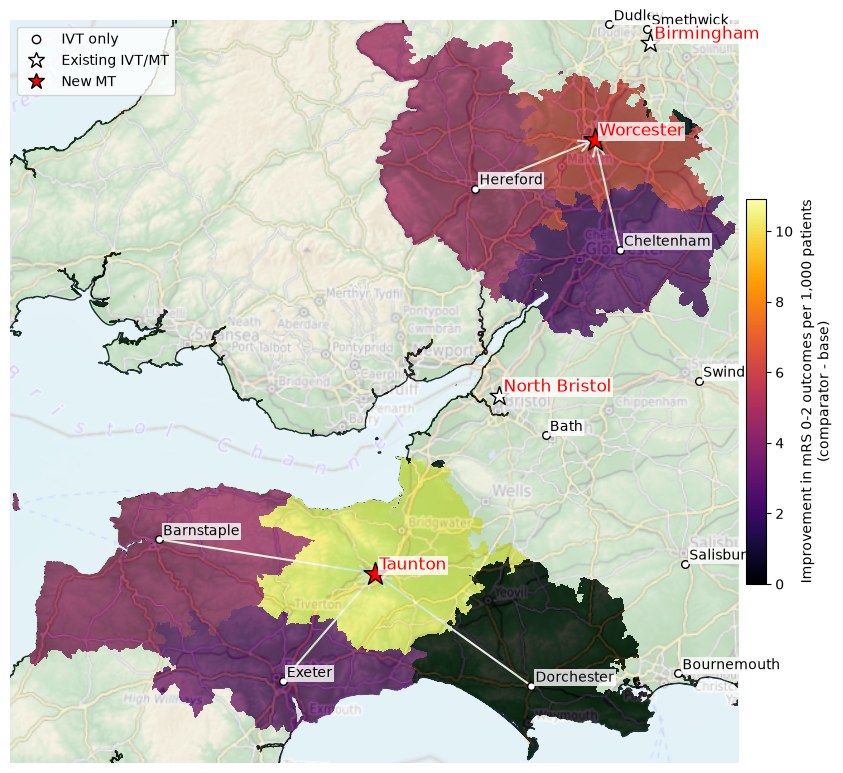

In [14]:
data = comparison_changed.copy()

column_to_plot = 'change_in_mrs_0-2_per_1000'

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1)

values = pd.to_numeric(data[column_to_plot], errors='coerce').astype(float)
valid_values = values[values.notnull()]
vmin, vmax = valid_values.min(), valid_values.max()
if vmin == vmax:
    vmax = vmin + 1

vin=0 # Manual set

cmap = plt.get_cmap('inferno')
norm = Normalize(vmin=vmin, vmax=vmax)

# Use a temporary numeric column; GeoPandas handles the color mapping.
data['_plot_value'] = values

data.plot(
    column='_plot_value',
    ax=ax,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    missing_kwds={'color': 'lightgrey'},
    antialiased=False,
    linewidth=0,
)

mappable = ScalarMappable(cmap=cmap, norm=Normalize(vmin=vmin, vmax=vmax))
mappable.set_array([])

norm = Normalize(vmin=0, vmax=vmax)
mappable.set_norm(norm)

for collection in ax.collections:
    collection.set_norm(norm)

fig.colorbar(
    mappable,
    ax=ax,
    shrink=0.5,
    pad=0.01,
    fraction=0.05,
    label='Improvement in mRS 0-2 outcomes per 1,000 patients\n(comparator - base)',
)

england.plot(ax=ax, edgecolor='k', facecolor='0.95', linewidth=1, zorder=0)

ivt_mask = pd.to_numeric(hospitals_gdf['Use_IVT'], errors='coerce').eq(1)
mt_mask = pd.to_numeric(hospitals_gdf['Use_MT'], errors='coerce').eq(1)
new_mt_mask = pd.to_numeric(hospitals_gdf['extra_MT_unit'], errors='coerce').eq(1)

hospitals_gdf.loc[ivt_mask].plot(
    ax=ax, edgecolor='k', facecolor='w', markersize=30, marker='o', zorder=99
)
hospitals_gdf.loc[mt_mask].plot(
ax=ax, edgecolor='k', facecolor='w', markersize=200, marker='*', zorder=99
)
hospitals_gdf.loc[new_mt_mask].plot(
ax=ax, edgecolor='k', facecolor='r', markersize=300, marker='*', zorder=99
)

# Add 'hopsital_city' labels for all IVT and MT hopsitals. Add it top right of hopsital marker. Use a smaller font size for MT hospitals and a larger font size for IVT hospitals. Use a different color for the text of MT hospitals to make it stand out.

# Get Use_IVT not in Use_MT and extra_MT_unit
IVT_only_mask = ivt_mask & ~mt_mask & ~new_mt_mask

for idx, row in hospitals_gdf.loc[IVT_only_mask].iterrows():
    ax.annotate(
        row['Hospital_City'],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords='offset points',
        fontsize=10,
        color='black',
        zorder=100,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1),
    )

for idx, row in hospitals_gdf.loc[mt_mask].iterrows():
    ax.annotate(
        row['Hospital_City'],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords='offset points',
        fontsize=12,
        color='red',
        zorder=100,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1),
    )

for idx, row in hospitals_gdf.loc[new_mt_mask].iterrows():
    ax.annotate(
        row['Hospital_City'],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords='offset points',
        fontsize=12,
        color='red',
        zorder=100,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1),
    )

ax.apply_aspect()
ax.set_axis_off()

# Apply limits to the plot based on the data bounds
ax.set_xlim(min_lng, max_lng)
ax.set_ylim(min_lat, max_lat)

ctx.add_basemap(
    ax,
    source="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
    crs="EPSG:27700",
    zoom="auto",
    alpha=0.25,  # 75% transparent
    zorder=2,
)

# Get all unique combinations of comparitor IVT units and MT units
unique_combinations = comparison_changed[['comparitor_ivt_unit', 'comparitor_mt_unit']].drop_duplicates()

# Draw arrows between the comparitor IVT units and MT units if both units if MT unit is in the extra_MT_unit list
for _, row in unique_combinations.iterrows():
    ivt_unit = row['comparitor_ivt_unit']
    mt_unit = row['comparitor_mt_unit']

    ivt_hospital = hospitals_gdf[hospitals_gdf['Postcode'] == ivt_unit]
    mt_hospital = hospitals_gdf[hospitals_gdf['Postcode'] == mt_unit]

    if not ivt_hospital.empty and not mt_hospital.empty:
        if mt_hospital.iloc[0]['extra_MT_unit'] == 1:
            ax.annotate(
                '',
                xy=(mt_hospital.geometry.x.values[0], mt_hospital.geometry.y.values[0]),
                xytext=(ivt_hospital.geometry.x.values[0], ivt_hospital.geometry.y.values[0]),
                arrowprops=dict(
                    arrowstyle='->',
                    color='white',
                    lw=1.5,
                    mutation_scale=20,
                ),
                zorder=1,
            )

# Add a key for the hospital markers
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='w', markeredgecolor='k', markersize=6, label='IVT only'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='w', markeredgecolor='k', markersize=12, label='Existing IVT/MT'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='r', markeredgecolor='k', markersize=12, label='New MT'),
]

ax.legend(handles=legend_elements, loc='upper left')

plt.savefig(f'./output/comparison_map_{output_name}.png', dpi=300, bbox_inches='tight')

plt.show()